## MTL Trajet: 12 Single-user Routine Change and Anomaly (Flag 12)

### Dataset Overview
Four weeks of dense daily trajectories for one user, including route geometry, weather condition, destination land use, purpose, transport mode, and timestamped GPS points.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Summarize the trip pattern and possible changes of the user and find anomalies from the usual behavior.

Role: Individual mobility-pattern analyst


Category: Single-user four-week routines, weather-conditioned work routes, shopping change, health visits, and an anomalous return trip

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display
points=pd.read_csv('trajectory_points.csv')


## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How are the user's motor-vehicle commute route variants associated with weather conditions?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

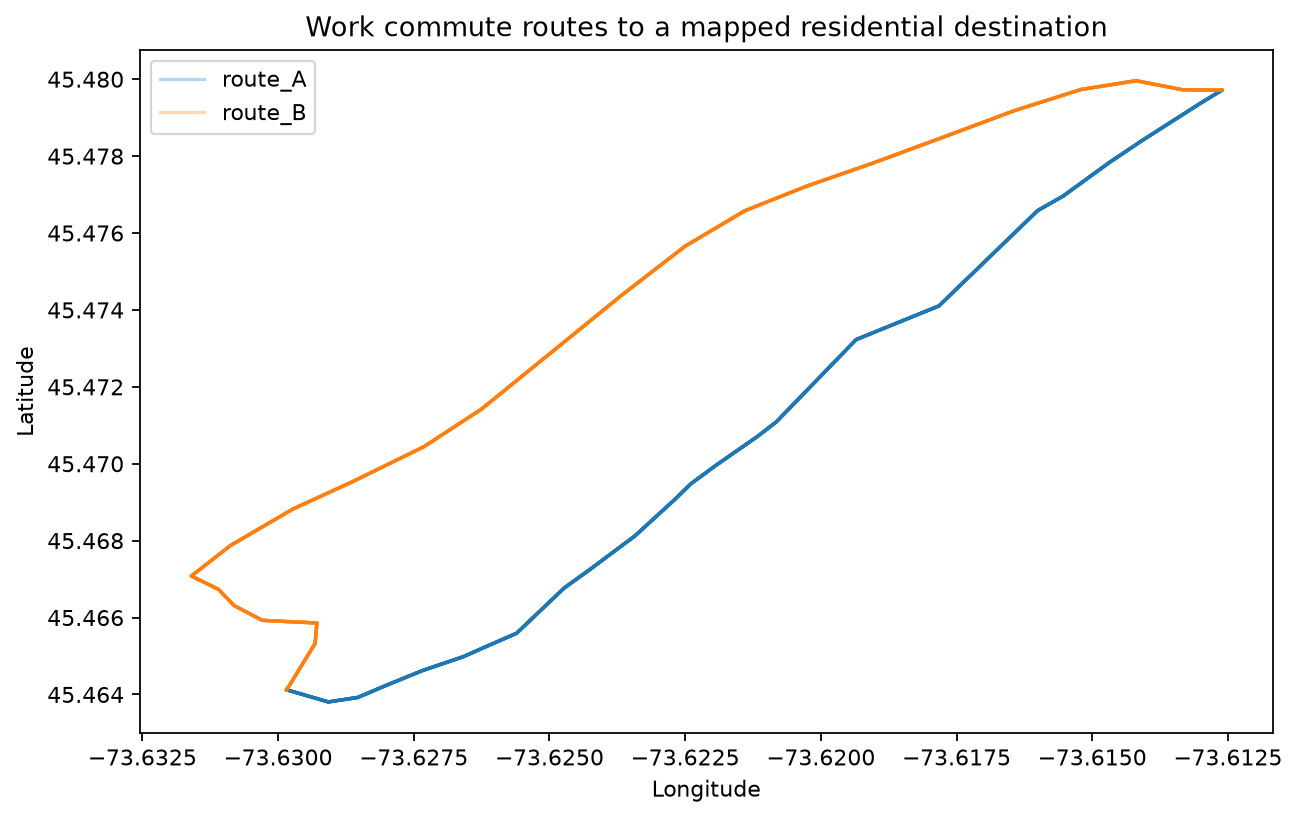

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
work=df[df.trip_role.eq('work_commute')]; print(work.groupby(['weather_condition','route_variant']).distance_km.agg(['count','mean'])); print(work.destination_land_use.value_counts())

from IPython.display import Image, display
display(Image(filename='visualizations/work_route_weather_pattern.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "work_route_weather_routine",
  "insight": "The user has two recurring motor-vehicle routes from the same origin to a work destination in a mapped residential area: route A is shorter and used on sunny days, while every rainy-day commute uses the longer route B detour.",
  "insight_type": "overall_pattern",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Work Route and Weather Pattern",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/work_route_weather_pattern.png"
  },
  "question": "How are the user's motor-vehicle commute route variants associated with weather conditions?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\nwork=df[df.trip_role.eq('work_commute')]; print(work.groupby(['weather_condition','route_variant']).distance_km.agg(['count','mean'])); print(work.destination_land_use.value_counts())\n",
  "insight_value": [
    {
      "weather_condition": "rainy",
      "route_variant": "route_B",
      "count": 12,
      "mean": 2.580675504
    },
    {
      "weather_condition": "sunny",
      "route_variant": "route_A",
      "count": 16,
      "mean": 2.290546538
    }
  ],
  "evidence": "Trip purpose is work; the official polygon at the work endpoint is Résidentiel. Work purpose does not imply an employment land-use category.",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "weather",
    "trip_purpose",
    "transport_mode",
    "gps_position",
    "land_use_reference",
    "trajectory_id"
  ]
}

### **Question 2**: How do the user's primary-shopping destination and transportation mode change across the four weeks?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

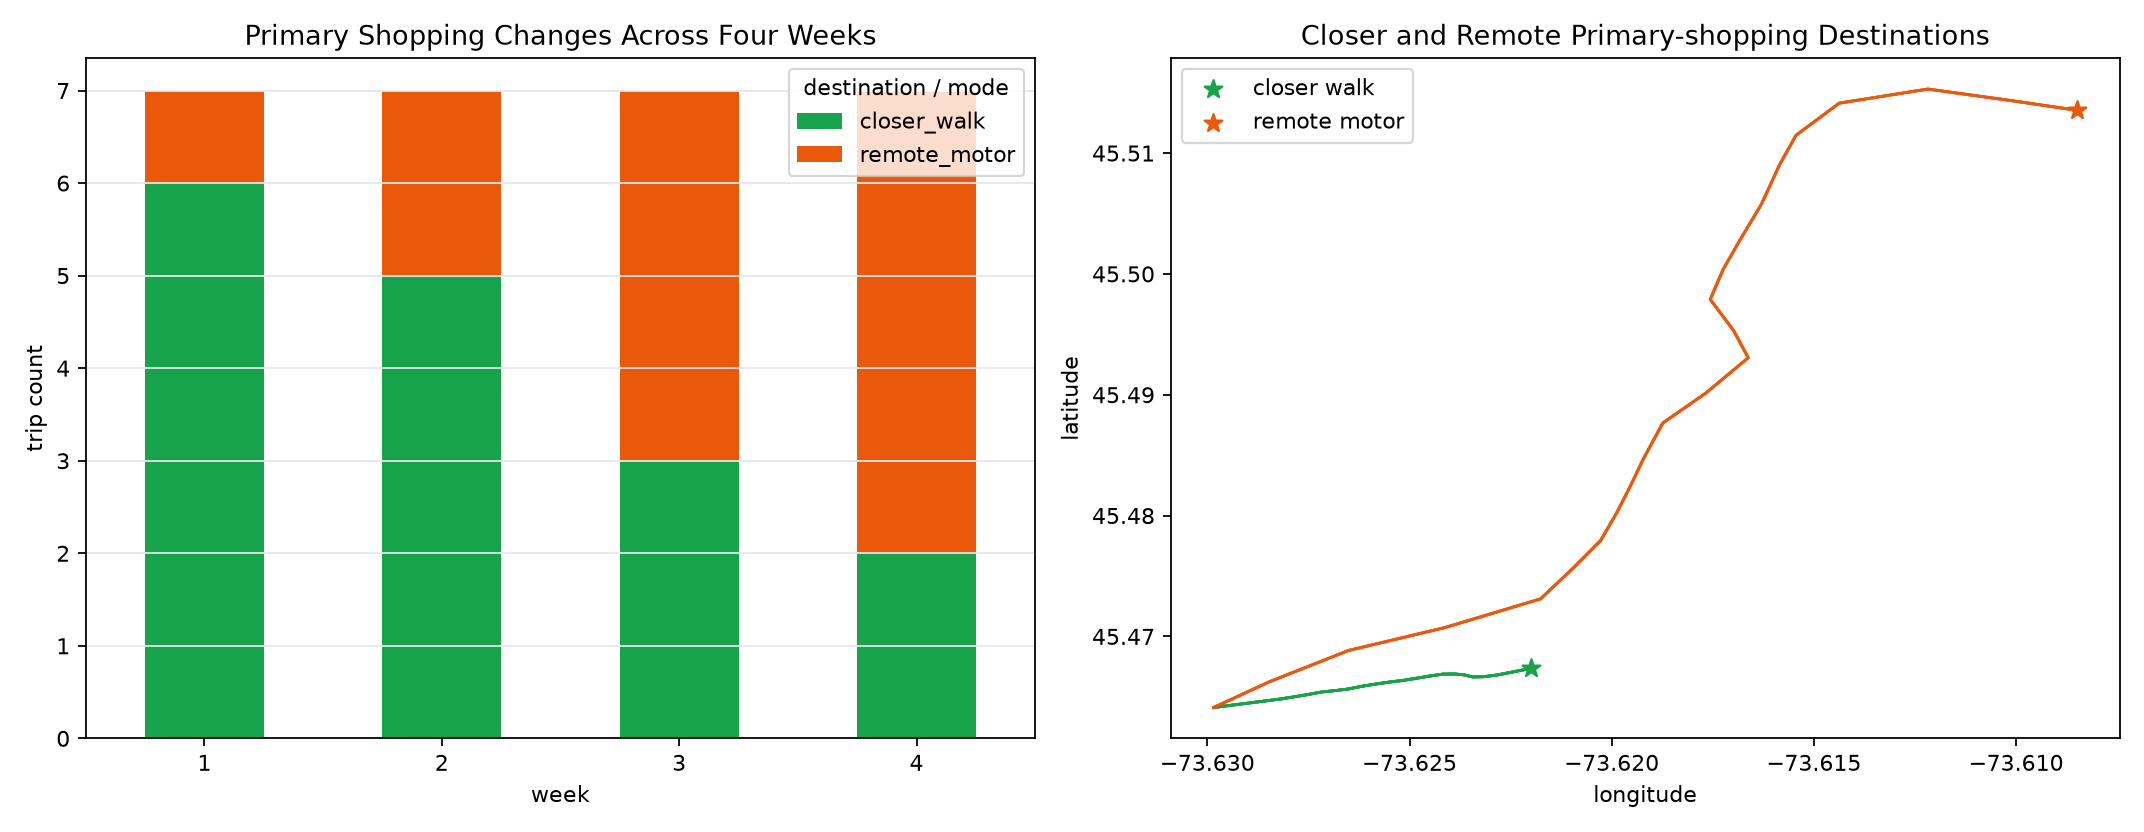

In [ ]:
pd.crosstab(df[df.trip_role.eq('primary_shopping')].week_index, df.route_variant)
from IPython.display import Image, display
display(Image(filename='visualizations/shopping_preference_change.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "shopping_mode_destination_change",
  "insight": "Across four weeks, shopping trips shift from a closer walking route toward a more remote motor-vehicle route.",
  "insight_type": "temporal_dynamics",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Shopping Preference Change",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/shopping_preference_change.png"
  },
  "question": "How do the user's primary-shopping destination and transportation mode change across the four weeks?",
  "code": "pd.crosstab(df[df.trip_role.eq('primary_shopping')].week_index, df.route_variant)",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "trip_purpose",
    "transport_mode",
    "gps_position"
  ]
}

### **Question 3**: On which weekday and at what time does the user's health-area travel occur?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

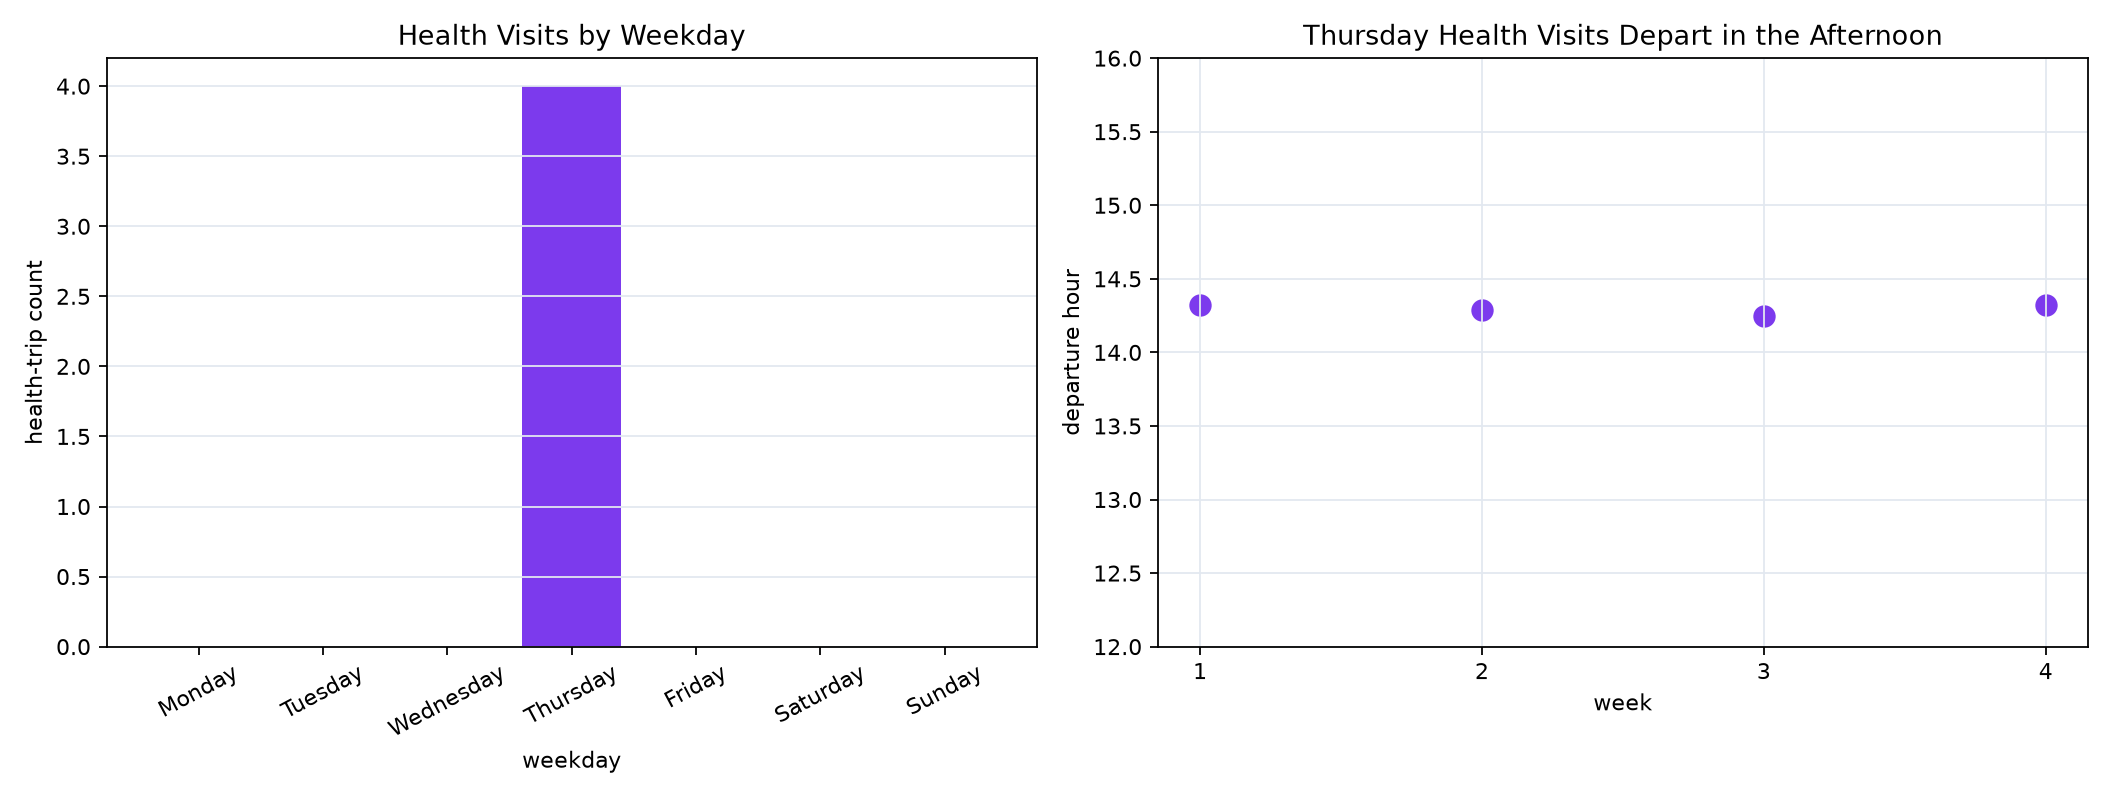

In [ ]:
df[df.purpose_group.eq('health')].groupby('weekday').start_hour.agg(['count','min','max','mean'])
from IPython.display import Image, display
display(Image(filename='visualizations/thursday_health_pattern.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "health_weekday_departure_pattern",
  "insight": "Health visits occur on Thursday afternoons, and their destination area differs from the work and shopping destinations.",
  "insight_type": "overall_pattern",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Thursday Health Pattern",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/thursday_health_pattern.png"
  },
  "question": "On which weekday and at what time does the user's health-area travel occur?",
  "code": "df[df.purpose_group.eq('health')].groupby('weekday').start_hour.agg(['count','min','max','mean'])",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "trip_purpose",
    "gps_position"
  ]
}

### **Question 4**: Does any trajectory depart from the user's usual distance and endpoint pattern?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

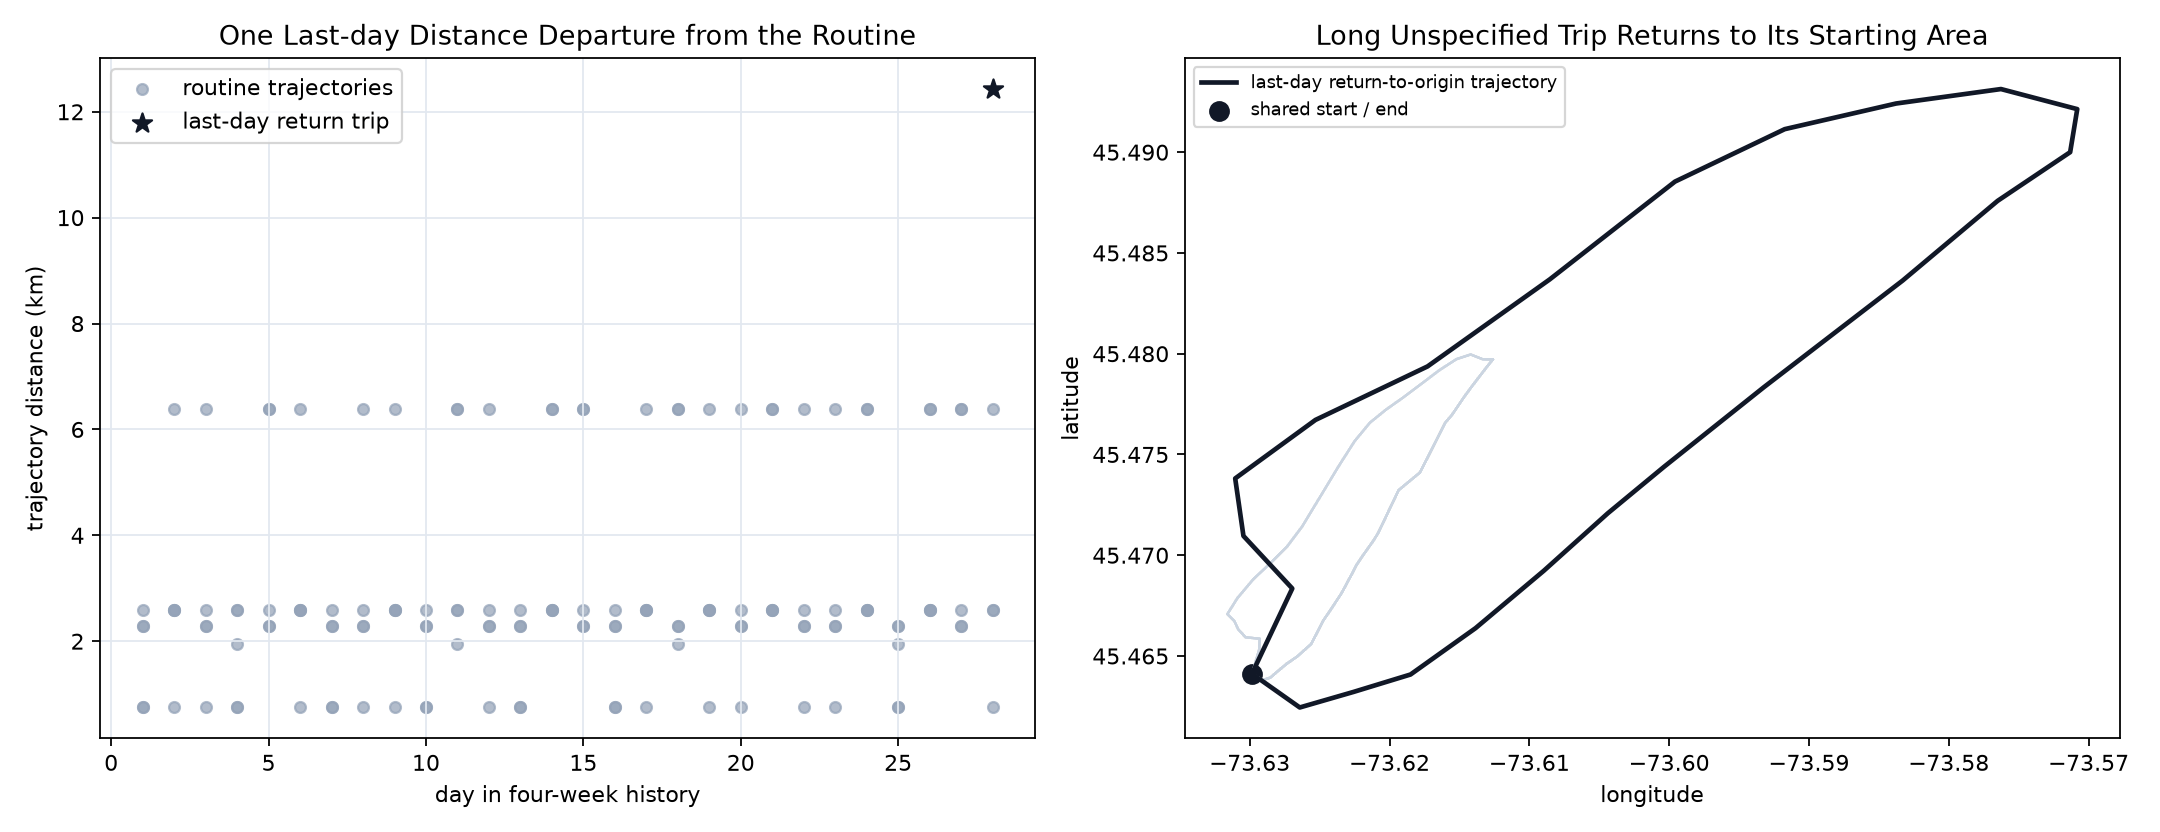

In [ ]:
df[['calendar_date','distance_km','purpose_group','returns_to_origin','is_anomaly']].sort_values('distance_km', ascending=False)
from IPython.display import Image, display
display(Image(filename='visualizations/last_day_return_trip_anomaly.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "single_user_routine_anomaly",
  "insight": "The final day contains the user's only clear anomaly: an unusually long purposeless motor-vehicle trip that returns to its origin.",
  "evidence": "The only clear departure from the routine occurs on the last day: an unusually long motor-vehicle trip with no declared purpose returns to its starting area with extremely long distance.",
  "insight_type": "exception_deviation",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Last-day Return Trip",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/last_day_return_trip_anomaly.png"
  },
  "question": "Does any trajectory depart from the user's usual distance and endpoint pattern?",
  "code": "df[['calendar_date','distance_km','purpose_group','returns_to_origin','is_anomaly']].sort_values('distance_km', ascending=False)",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "trip_purpose",
    "transport_mode",
    "gps_position"
  ]
}

### Summary of Findings (Flag 12)

The user has two recurring motor-vehicle routes from the same origin to a work destination in a mapped residential area: route A is shorter and used on sunny days, while every rainy-day commute uses the longer route B detour. Across four weeks, shopping trips shift from a closer walking route toward a more remote motor-vehicle route. Health visits occur on Thursday afternoons, and their destination area differs from the work and shopping destinations. The final day contains the user's only clear anomaly: an unusually long purposeless motor-vehicle trip that returns to its origin.
